# Student outcome analysis

Predict whether a student graduates, drops out, or is still enrolled at the end of the program's normal length. Each row in `data.csv` is one student. This notebook is a first pass: explore the table, plot a few relationships, and fit a simple baseline model.


## 1. Setup


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_SEED = 42
DATA_PATH = Path("data.csv")
pd.set_option("display.max_columns", 40)


## 2. Load the data


In [3]:
df = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig")
df.columns = df.columns.str.strip()

assert df.shape == (4424, 37), df.shape
assert set(df["Target"]) == {"Dropout", "Enrolled", "Graduate"}

print(df.shape)
df.head()


(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 3. Exploratory analysis

`Target` has three classes. The other columns are already numeric: demographics and application details, grades from the first two semesters, and the economic indicators for the year of enrollment.


In [4]:
print(df["Target"].value_counts().to_string())
print()
print(f"missing values: {int(df.isna().sum().sum())}")


Target
Graduate    2209
Dropout     1421
Enrolled     794

missing values: 0


In [5]:
summary_cols = [
    "Age at enrollment",
    "Admission grade",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
]
df.groupby("Target")[summary_cols].mean().round(2)


,Age at enrollment,Admission grade,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade)
Target,,,,,
Dropout,26.07,124.96,2.55,1.94,5.90
Enrolled,22.37,125.53,4.32,4.06,11.12
Graduate,21.78,128.79,6.23,6.18,12.70


## 4. Visualizations

Three views: how common each outcome is, the age mix, and how many second-semester units students in each outcome had approved.


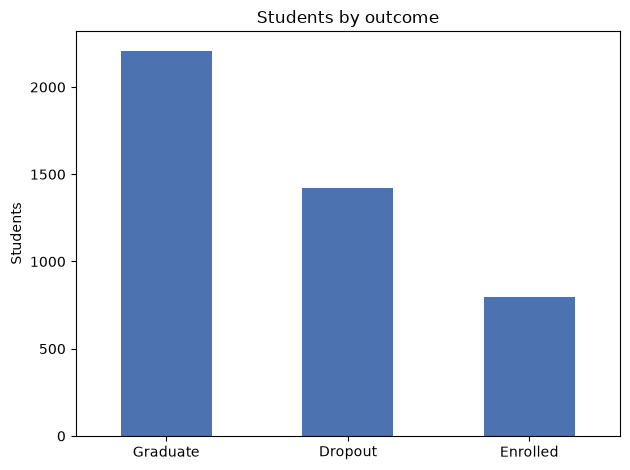

In [6]:
df["Target"].value_counts().plot(kind="bar", color="#4C72B0")
plt.title("Students by outcome")
plt.ylabel("Students")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


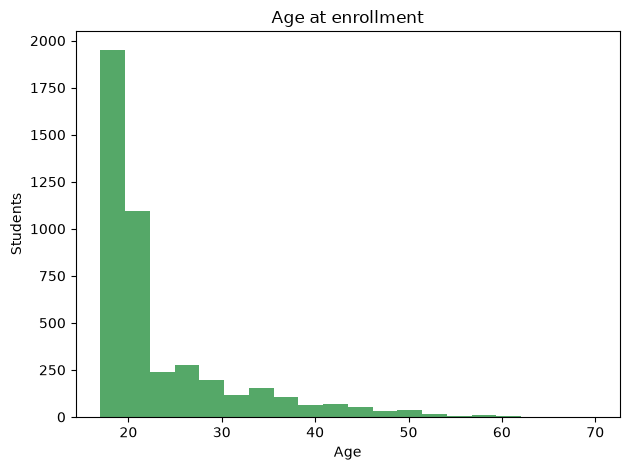

In [7]:
df["Age at enrollment"].plot(kind="hist", bins=20, color="#55A868")
plt.title("Age at enrollment")
plt.xlabel("Age")
plt.ylabel("Students")
plt.tight_layout()
plt.show()


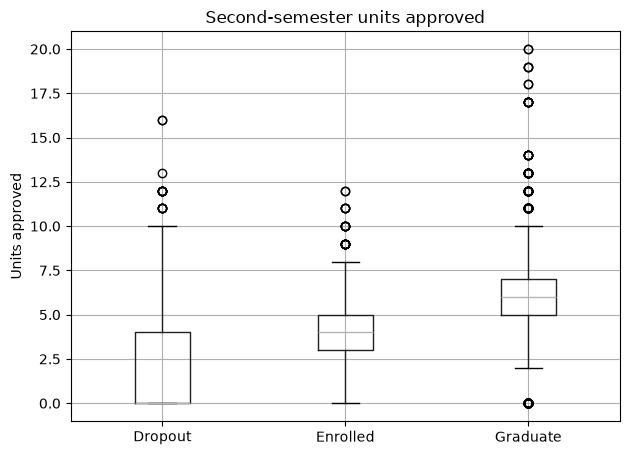

In [8]:
df.boxplot(column="Curricular units 2nd sem (approved)", by="Target")
plt.suptitle("")
plt.title("Second-semester units approved")
plt.xlabel("")
plt.ylabel("Units approved")
plt.tight_layout()
plt.show()


## 5. Modelling

Every column except `Target` is an input. A logistic regression, fit on a stratified 80/20 split, is the baseline. Semester grades are included, so this uses information from after the student has already started the program.


In [9]:
X = df.drop(columns="Target")
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
)
model.fit(X_train, y_train)
print(f"train rows: {len(X_train)}")
print(f"test rows: {len(X_test)}")


train rows: 3539
test rows: 885


## 6. Results

Accuracy is the share of test students given the right label. The report breaks that down by class, and the confusion matrix shows which outcomes are mixed up.


test accuracy: 0.768

              precision    recall  f1-score   support

     Dropout       0.79      0.77      0.78       284
    Enrolled       0.52      0.33      0.41       159
    Graduate       0.80      0.93      0.86       442

    accuracy                           0.77       885
   macro avg       0.71      0.68      0.68       885
weighted avg       0.75      0.77      0.75       885



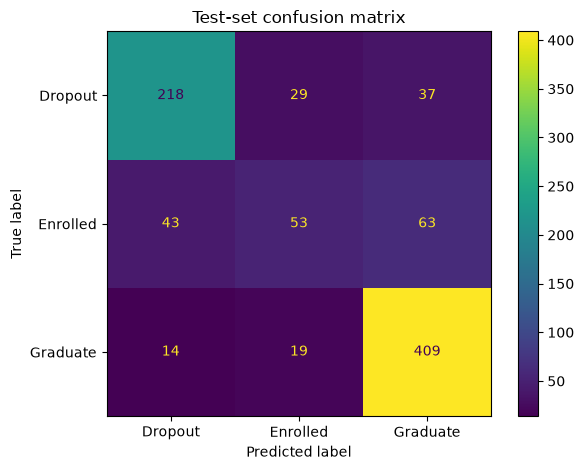

In [10]:
predicted = model.predict(X_test)
print(f"test accuracy: {model.score(X_test, y_test):.3f}")
print()
print(classification_report(y_test, predicted))

ConfusionMatrixDisplay.from_predictions(y_test, predicted)
plt.title("Test-set confusion matrix")
plt.tight_layout()
plt.show()
